In [2]:
# Instalar e importar librerías necesarias
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import matplotlib.pyplot as plt
import seaborn as sns

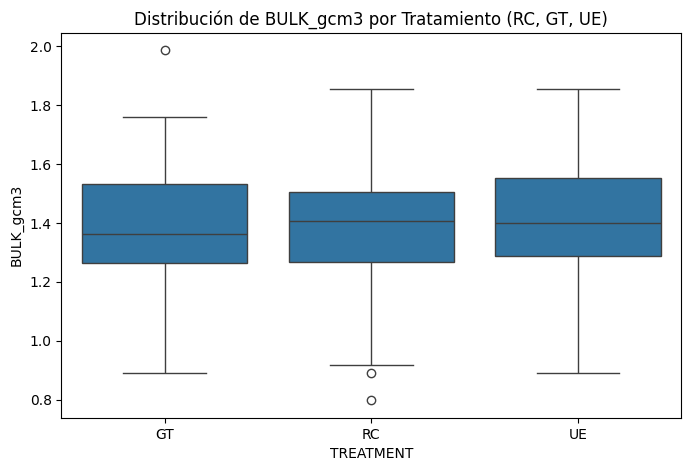

--- RESUMEN DEL MODELO MIXTO ---
            Mixed Linear Model Regression Results
Model:              MixedLM   Dependent Variable:   BULK_gcm3
No. Observations:   81        Method:               REML     
No. Groups:         3         Scale:                0.0399   
Min. group size:    27        Log-Likelihood:       6.8539   
Max. group size:    27        Converged:            Yes      
Mean group size:    27.0                                     
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           1.383    0.111 12.508 0.000  1.166  1.599
C(TREATMENT)[T.RC] -0.028    0.054 -0.512 0.609 -0.134  0.079
C(TREATMENT)[T.UE]  0.023    0.054  0.430 0.667 -0.083  0.130
Group Var           0.032    0.171                           


--- PRUEBA DE CONTRASTES (TUKEY HSD) ---
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 me

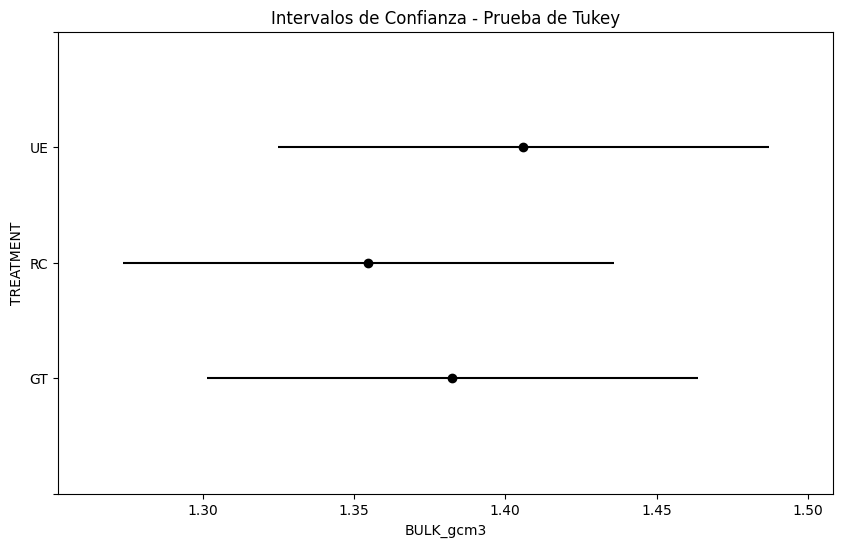

In [5]:
# 1. CARGAR LOS DATOS
# Asegúrate de que el archivo 'Densidad aparente.xlsx' esté subido a tu entorno de Colab
df = pd.read_excel('Densidad aparente.xlsx', sheet_name='TOTAL')

# 2. LIMPIEZA Y FILTRADO
# Asegurarnos de que los nombres de las columnas no tengan espacios extra
df.columns = df.columns.str.strip()

# Filtrar estrictamente los 3 tratamientos solicitados: RC, GT y UE
tratamientos_deseados = ['RC', 'GT', 'UE']
df_fil = df[df['TREATMENT'].isin(tratamientos_deseados)].copy()

# Eliminar posibles valores nulos en las columnas de interés
df_fil = df_fil.dropna(subset=['BULK_gcm3', 'TREATMENT', 'SITE'])

# 3. VISUALIZACIÓN PREVIA
plt.figure(figsize=(8, 5))
sns.boxplot(x='TREATMENT', y='BULK_gcm3', data=df_fil)
plt.title('Distribución de BULK_gcm3 por Tratamiento (RC, GT, UE)')
plt.show()

# 4. MODELO LINEAL MIXTO (LMM)
# Variable respuesta: BULK_gcm3 | Efecto fijo: TREATMENT | Efecto aleatorio: SITE
print("--- RESUMEN DEL MODELO MIXTO ---")
modelo_mixto = smf.mixedlm("BULK_gcm3 ~ C(TREATMENT)", df_fil, groups=df_fil["SITE"])
resultado_mixto = modelo_mixto.fit()
print(resultado_mixto.summary())

# 5. PRUEBAS DE CONTRASTE (POST-HOC)
# Prueba de Tukey para ver las diferencias específicas entre RC, GT y UE
print("\n--- PRUEBA DE CONTRASTES (TUKEY HSD) ---")
tukey = pairwise_tukeyhsd(endog=df_fil['BULK_gcm3'],
                          groups=df_fil['TREATMENT'],
                          alpha=0.05)
print(tukey)

# Graficar los intervalos de confianza del Tukey
tukey.plot_simultaneous(xlabel='BULK_gcm3', ylabel='TREATMENT')
plt.title('Intervalos de Confianza - Prueba de Tukey')
plt.show()